In [3]:
%load_ext autoreload
%autoreload 2

import numpy as np
import os
import sys
import torch

sys.path.append(os.path.join(os.getcwd(), '../../../preprint'))
from preprint import paths

from compcats.models import resnet50_imagenet1kv2, resnet18_imagenet1kv1, vitb14_dinov2

MODELS_DIR = '../../../preprint/models'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
def probe_model(model):
    """
        Break into the model and extract the first conv layer weights for a quick test bed model.
        The output will be an executable torch model that can be used for receptive field estimation.
        Input:
            model: a PyTorch model
        Output:
            probe_model(torch.nn.Module): extracted first conv layer weights
    """
    model.eval()
    first_conv_layer = model.model.patch_embed.proj
    probe_model = torch.nn.Sequential(first_conv_layer)
    return probe_model

In [10]:
gt_model = vitb14_dinov2.get_model()
gt_layer_weights = gt_model.model.patch_embed.proj.weight.detach().cpu() # Kernel weights of the first conv layer (patch embedding), shape: (768, 3, 14, 14)

Using cache found in /Users/adipani3/.cache/torch/hub/facebookresearch_dinov2_main


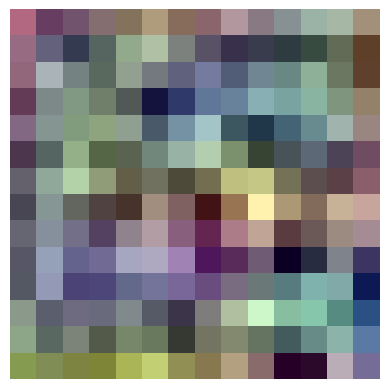

In [21]:
filter = gt_layer_weights[300]  # Get the first filter
# SHow filter as an image using torchvision
import torchvision.transforms as transforms
import torchvision.utils as vutils
import matplotlib.pyplot as plt
# Normalize filter to [0, 1] for visualization
filter_min = filter.min()
filter_max = filter.max()
filter_norm = (filter - filter_min) / (filter_max - filter_min)
# Add batch dimension
filter_norm = filter_norm.unsqueeze(0)
# Create a grid of images
grid = vutils.make_grid(filter_norm, nrow=1)
# Convert to numpy for plotting
np_grid = grid.numpy().transpose((1, 2, 0))
plt.imshow(np_grid)
plt.axis('off')
plt.show()

In [22]:
gt_layer_weights.shape

torch.Size([768, 3, 14, 14])

In [15]:
probe_model = probe_model(gt_model)
print(probe_model)

Sequential(
  (0): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
)


In [17]:
probe_model(torch.randn(1, 3, 224, 224)).shape  # Example input tensor with batch size 1 and image size 224x224

torch.Size([1, 768, 16, 16])